# Prédiction du risque de défaut de crédit

**Auteur :** Mathis Collana - **Données :** [Credit Risk Dataset (Kaggle)](https://www.kaggle.com/datasets/laotse/credit-risk-dataset)

---

## Objectif

Prédire si un emprunteur fera défaut sur son prêt (loan_status) à partir de ses
caractéristiques personnelles (âge, revenu, statut de logement, ancienneté) et des
caractéristiques du prêt (montant, taux, motif, grade).

Le jeu de données contient **32 581 dossiers de crédit** et 12 variables.

## Démarche

1. **Exploration** - comprendre la distribution des variables et leur lien avec le défaut
2. **Nettoyage** - valeurs impossibles et doublons
3. **Préparation** - séparation train/test, imputation, encodage, normalisation
4. **Modélisation** - régression logistique
5. **Évaluation** - matrice de confusion, précision, rappel, AUC

---
## 1 :  Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Affichage des 5 premières observations afin d'avoir un aperçu du jeu de données.


---
## 2 : Inspection des données

Premier réflexe sur un jeu de données inconnu : en connaître les dimensions, les types
de chaque colonne, les valeurs manquantes et les doublons.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [5]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())
print("\nLignes dupliquées :", df.duplicated().sum())

Valeurs manquantes par colonne :
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Lignes dupliquées : 165


**On retient que :**

- `loan_int_rate` : 3 116 valeurs manquantes 
- `person_emp_length` : 895 valeurs manquantes 
- 165 lignes strictement dupliquées

Les manquants sont trop nombreux pour supprimer les lignes concernées : on les
**imputera**.

### 2.1 : Équilibre de la variable cible

Avant toute modélisation, il faut savoir si les deux classes sont équilibrées : cela
conditionne le choix des métriques d'évaluation.

In [6]:
print(df["loan_status"].value_counts())
print()
print(df["loan_status"].value_counts(normalize=True))

loan_status
0    25473
1     7108
Name: count, dtype: int64

loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64


Le jeu est **modérément déséquilibré** : environ 78 % de non-défauts contre 22 % de défauts.

**Conséquence importante :** un modèle qui prédirait « pas de défaut » pour tout le monde
aurait déjà 78 % de bonnes réponses sans rien comprendre. L'*accuracy* sera donc une
métrique trompeuse 

---
## 3 : Analyse exploratoire : le revenu

On explore d'abord la variable `person_income`, qui est intuitivement liée à la capacité
de remboursement.

In [7]:
print(df["person_income"].describe())
print()
print("Revenu moyen  :", round(df["person_income"].mean(), 2))
print("Revenu médian :", df["person_income"].median())

count    3.258100e+04
mean     6.607485e+04
std      6.198312e+04
min      4.000000e+03
25%      3.850000e+04
50%      5.500000e+04
75%      7.920000e+04
max      6.000000e+06
Name: person_income, dtype: float64

Revenu moyen  : 66074.85
Revenu médian : 55000.0


La **moyenne (66 075) est supérieure à la médiane (55 000)**. On a donc une distribution étirée vers la droite, où quelques très hauts revenus tirent la moyenne
vers le haut. 75 % des personnes gagnent moins de 79 200.

La valeur maximale est de 6 000 000. Elle est extrême, mais **pas impossible** - on peut
tout à fait avoir un emprunteur très fortuné. On ne la supprime donc pas.

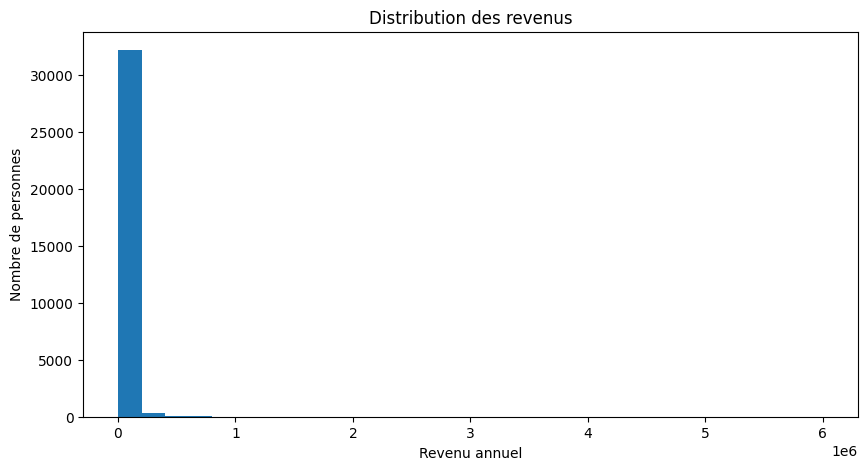

In [8]:
plt.figure(figsize=(10, 5))
plt.hist(df["person_income"], bins=30)
plt.title("Distribution des revenus")
plt.xlabel("Revenu annuel")
plt.ylabel("Nombre de personnes")
plt.show()

L'histogramme est illisible : les quelques revenus au-delà du million étirent l'axe
horizontal et écrasent toute l'information utile. Un **boxplot** sera plus parlant pour
visualiser la dispersion réelle.

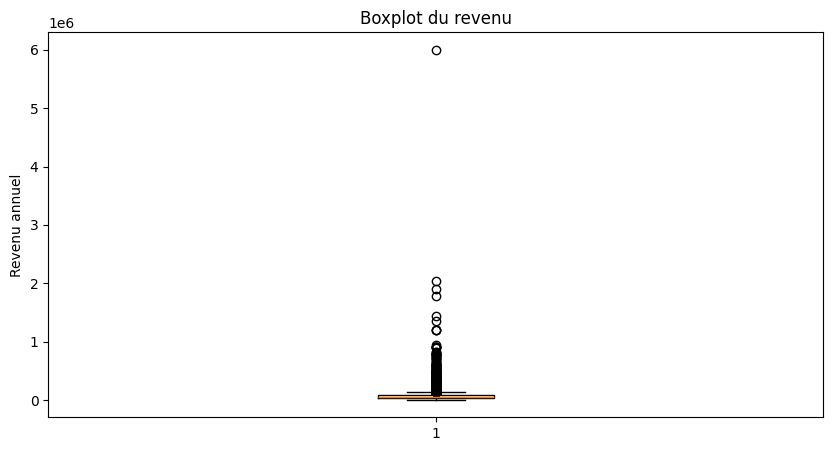

Les 10 revenus les plus élevés :
32297    6000000
30049    2039784
32546    1900000
32497    1782000
31924    1440000
31922    1362000
17833    1200000
29119    1200000
29120    1200000
17834     948000
Name: person_income, dtype: int64


In [9]:
plt.figure(figsize=(10, 5))
plt.boxplot(df["person_income"])
plt.title("Boxplot du revenu")
plt.ylabel("Revenu annuel")
plt.show()

print("Les 10 revenus les plus élevés :")
print(df["person_income"].nlargest(10))

Le boxplot confirme que la dispersion se situe très en dessous du million : les 9 plus
gros revenus dépassent tous 1 000 000 et sont visuellement isolés du reste.

### 3.1 : Détection des valeurs atypiques par la méthode IQR

Méthode classique : on calcule l'écart interquartile `IQR = Q3 - Q1`, puis on considère
comme atypique toute valeur en dehors de l'intervalle
`[Q1 - 1.5 × IQR ; Q3 + 1.5 × IQR]`.

In [10]:
def detect_outliers(df, variable):
    """Détecte les valeurs atypiques d'une variable par la méthode de l'écart interquartile.

    Retourne les lignes situées hors des bornes [Q1 - 1.5*IQR ; Q3 + 1.5*IQR].
    """
    q1 = df[variable].quantile(0.25)
    q3 = df[variable].quantile(0.75)
    iqr = q3 - q1
    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr

    masque = (df[variable] < borne_basse) | (df[variable] > borne_haute)
    outliers = df[masque]

    print("Variable    :", variable)
    print("Q1          :", q1)
    print("Q3          :", q3)
    print("IQR         :", iqr)
    print("Borne basse :", borne_basse)
    print("Borne haute :", borne_haute)
    print("Nombre de valeurs atypiques :", len(outliers))

    return outliers


outliers = detect_outliers(df, "person_income")

Variable    : person_income
Q1          : 38500.0
Q3          : 79200.0
IQR         : 40700.0
Borne basse : -22550.0
Borne haute : 140250.0
Nombre de valeurs atypiques : 1484


In [11]:
print(outliers["person_income"].sort_values().head())

17543    140300
15522    140300
27469    140304
31782    140400
31865    140787
Name: person_income, dtype: int64


**Interprétation : un point méthodologique important.**

La méthode IQR identifie 1 484 valeurs « atypiques ». La fonction fonctionne bien : la
borne haute calculée est 140 250 et le premier revenu détecté est 140 300.

Mais il faut distinguer deux notions que l'on confond souvent :

- **Valeur atypique** (*outlier*) : Valeur éloignée du gros de la distribution, mais **réelle** que l'on conserve.
- **Erreur de données** : Valeur **impossible** Règles de cohérence métier que l'on supprime.

Ces 1 484 lignes sont des personnes à hauts revenus : elles sont statistiquement
éloignées de la moyenne, mais parfaitement plausibles. **Les supprimer reviendrait à
écarter arbitrairement les emprunteurs aisés**, ce qui biaiserait le modèle.

On les conserve donc. Les vraies erreurs seront traitées en partie 4, avec des règles
de bon sens et non une formule statistique.

### 3.2 : Le revenu discrimine-t-il le défaut ?

C'est la question centrale de l'exploration : chaque variable doit être analysée
**par rapport à la cible**.

In [12]:
df.groupby("loan_status")["person_income"].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
0,25473.0,70804.361559,66568.802606,7000.0,42000.0,60000.0,84000.00,6000000.0
1,7108.0,49125.652223,36907.376527,4000.0,30000.0,41498.0,59497.75,703800.0


Les personnes ayant fait défaut ont des revenus globalement plus faibles. On note aussi
que le revenu maximum du groupe en défaut (703 800) est bien inférieur à celui du groupe
sans défaut (6 000 000) : les très hauts revenus ne font quasiment jamais défaut.

Moyenne et médiane sont éloignées dans les deux groupes, ce qui confirme l'influence des
valeurs extrêmes.

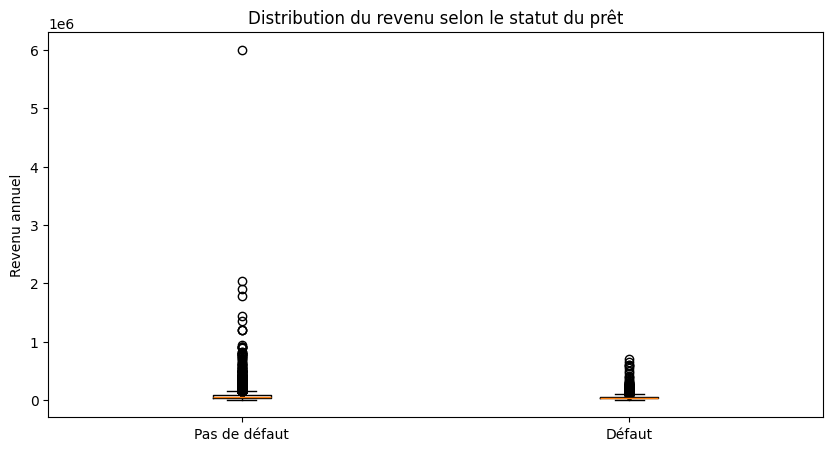

In [13]:
revenus_sans_defaut = df[df["loan_status"] == 0]["person_income"]
revenus_avec_defaut = df[df["loan_status"] == 1]["person_income"]

plt.figure(figsize=(10, 5))
plt.boxplot([revenus_sans_defaut, revenus_avec_defaut],
            tick_labels=["Pas de défaut", "Défaut"])
plt.title("Distribution du revenu selon le statut du prêt")
plt.ylabel("Revenu annuel")
plt.show()

La distribution des revenus est globalement plus basse chez les personnes ayant fait
défaut : médiane et quartiles sont inférieurs.

L'échelle reste cependant écrasée par les revenus extrêmes. On refait donc le graphique
en excluant le 1 % de revenus les plus élevés, pour mieux voir les boîtes.

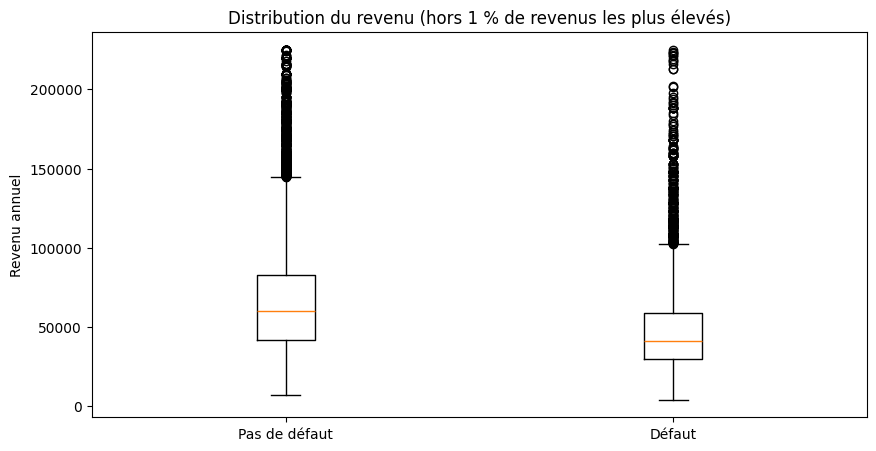

In [14]:
seuil = df["person_income"].quantile(0.99)   # coupe identique pour les deux groupes

revenus_sans_defaut_zoom = df[(df["loan_status"] == 0) & (df["person_income"] <= seuil)]["person_income"]
revenus_avec_defaut_zoom = df[(df["loan_status"] == 1) & (df["person_income"] <= seuil)]["person_income"]

plt.figure(figsize=(10, 5))
plt.boxplot([revenus_sans_defaut_zoom, revenus_avec_defaut_zoom],
            tick_labels=["Pas de défaut", "Défaut"])
plt.title("Distribution du revenu (hors 1 % de revenus les plus élevés)")
plt.ylabel("Revenu annuel")
plt.show()

Le graphique zoomé confirme l'observation précédente. On note toutefois un
**recouvrement important entre les deux boîtes** : le revenu seul ne suffit pas à
séparer les deux populations. Il apporte de l'information, mais devra être combiné à
d'autres variables.

---
## 4 : Nettoyage des données

### 4.1 : Valeurs impossibles

Contrairement aux valeurs atypiques vues plus haut, il s'agit ici de valeurs
**logiquement impossibles**, donc d'erreurs de saisie. Deux contrôles :

- **Âge supérieur à 100 ans.** Les âges valides culminent à 94, puis on trouve des
  valeurs de 123 et 144. Le seuil de 100 tombe dans un « trou » de la distribution :
  il ne coupe aucune valeur légitime.
- **Ancienneté supérieure à l'âge.** On ne peut pas avoir travaillé plus longtemps
  qu'on a vécu. Ce contrôle **relationnel** est plus robuste qu'un seuil arbitraire,
  car il découle de la logique du problème et non d'un chiffre choisi au hasard.

In [15]:
masque_incoherent = df["person_emp_length"] > df["person_age"]   # impossible
masque_age = df["person_age"] > 100                              # impossible

masque_fautif = masque_incoherent | masque_age

df_clean = df[~masque_fautif]

print("Avant :", df.shape)
print("Après :", df_clean.shape)
print("Lignes supprimées :", df.shape[0] - df_clean.shape[0])

Avant : (32581, 12)
Après : (32574, 12)
Lignes supprimées : 7


7 lignes supprimées, soit 0,02 % du jeu de données, une perte négligeable.

Ce total de 7 (= 5 + 2) confirme au passage que les deux anomalies ne se chevauchent
pas : aucune ligne ne cumulait un âge impossible **et** une ancienneté incohérente.

### 4.2 : Doublons

Le jeu ne contient **aucun identifiant unique** (ni numéro de client, ni numéro de prêt).
Une ligne strictement dupliquée signifierait donc que deux personnes partagent
exactement le même âge, le même revenu à l'euro près, le même montant de prêt, la même
ancienneté, le même motif et le même taux - sur les 12 colonnes simultanément.

C'est hautement improbable. On considère donc ces lignes comme des **duplications
techniques** et on les supprime.

> **Nuance à retenir :** cette décision n'est pas universelle. Dans une table de
> transactions, deux achats identiques le même jour sont parfaitement légitimes. La
> question à se poser est toujours : *qu'est-ce qu'une ligne représente ?*

In [16]:
n_avant = df_clean.shape[0]

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Doublons retirés :", n_avant - df_clean.shape[0])
print("Dimensions finales :", df_clean.shape)

Doublons retirés : 165
Dimensions finales : (32409, 12)


Le reset_index(drop=True) renumérote les lignes de 0 à N. Après une suppression,
l'index conserve en effet des « trous » qui peuvent provoquer des bugs d'alignement
plus tard.

---
## 5 : Préparation des données

### 5.1 Séparation train / test

On sépare les variables explicatives (`X`) de la cible (`y`), puis on découpe en deux
jeux : 80 % pour l'entraînement, 20 % pour le test.

**Pourquoi séparer ?** Évaluer un modèle sur des données qu'il a déjà vues donnerait une
note mensongère. Comme un examen dont on aurait donné les réponses à l'avance. Le jeu
de test simule les **futurs clients inconnus**.

Deux réglages importants :

- `random_state=42` fige le tirage aléatoire : le découpage sera identique à chaque
  exécution. C'est la **reproductibilité**, essentielle pour comparer des résultats.
- `stratify=y` impose la même proportion de défauts dans le train et dans le test.
  Indispensable ici, puisque la cible est déséquilibrée.

In [17]:
y = df_clean["loan_status"]
X = df_clean.drop(columns="loan_status")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# copies explicites, pour éviter les avertissements de pandas lors des modifications
X_train = X_train.copy()
X_test = X_test.copy()

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

X_train : (25927, 11)
X_test  : (6482, 11)


In [29]:
print("Proportion de défauts - train :")
print(y_train.value_counts(normalize=True))
print("\nProportion de défauts - test :")
print(y_test.value_counts(normalize=True))

Proportion de défauts - train :
loan_status
0    0.781309
1    0.218691
Name: proportion, dtype: float64

Proportion de défauts - test :
loan_status
0    0.78124
1    0.21876
Name: proportion, dtype: float64


**Vérification :** le test représente bien 20 % des lignes (6 482 sur 32 409), et les
deux jeux comportent 11 colonnes (12 moins la cible).

Surtout, la proportion de défauts est **identique à la quatrième décimale** entre train
(0,2187) et test (0,2188) : la stratification a fonctionné. L'évaluation sera juste.

### 5.2 Imputation des valeurs manquantes

On remplace les valeurs manquantes de `loan_int_rate` et `person_emp_length` par la
**médiane** de chaque colonne. On préfère la médiane à la moyenne car elle résiste aux
valeurs extrêmes, ce qui est précisément le cas ici, comme l'a montré l'exploration.

**Point méthodologique central :** les médianes sont calculées **sur le train uniquement**,
puis appliquées aux deux jeux. Si on les calculait sur l'ensemble des données, une
information issue du test se glisserait dans l'entraînement : c'est la **fuite de
données**. Le test doit rester un inconnu total, comme un examen que l'on découvre le
jour J.

In [19]:
# les médianes sont calculées sur le TRAIN uniquement
mediane_taux = X_train["loan_int_rate"].median()
mediane_emp = X_train["person_emp_length"].median()

print("Médiane du taux d'intérêt (train) :", mediane_taux)
print("Médiane de l'ancienneté (train)   :", mediane_emp)

# on les applique aux deux jeux
X_train["loan_int_rate"] = X_train["loan_int_rate"].fillna(mediane_taux)
X_train["person_emp_length"] = X_train["person_emp_length"].fillna(mediane_emp)

X_test["loan_int_rate"] = X_test["loan_int_rate"].fillna(mediane_taux)
X_test["person_emp_length"] = X_test["person_emp_length"].fillna(mediane_emp)

Médiane du taux d'intérêt (train) : 10.99
Médiane de l'ancienneté (train)   : 4.0


In [30]:
print("Manquants restants, train :", X_train.isnull().sum().sum())
print("Manquants restants, test  :", X_test.isnull().sum().sum())

Manquants restants, train : 0
Manquants restants, test  : 0


Zéro valeur manquante de part et d'autre : l'imputation est validée.

### 5.3 Encodage des variables catégorielles

Un modèle de machine learning ne manipule que des **nombres**. Mais quatre colonnes
contiennent du texte : person_home_ownership, loan_intent, loan_grade et
cb_person_default_on_file.

In [21]:
# colonnes contenant du texte
X_train.dtypes[X_train.dtypes == "object"].index.tolist()

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

**Pourquoi le one-hot encoding ?**

La solution naïve consisterait à numéroter les catégories (RENT = 0, OWN = 1,
MORTGAGE = 2…). Mais cela créerait un **ordre et des distances qui n'existent pas** :
le modèle croirait qu'être propriétaire est « plus grand » qu'être locataire.

Le *one-hot encoding* crée à la place **une colonne binaire par catégorie** : chaque
personne a un 1 dans la colonne correspondant à sa catégorie, et des 0 partout ailleurs.
Aucune hiérarchie factice n'est introduite.

**Pourquoi aligner les colonnes ?** Si une catégorie rare était présente dans un jeu et
absente de l'autre, train et test se retrouveraient avec des colonnes différentes. Le
modèle, qui attend un nombre fixe de colonnes, planterait. `align` force le test à
adopter exactement les colonnes du train, en remplissant de 0 celles qui manquent.

In [22]:
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

# on aligne les colonnes du test sur celles du train (le train fait référence)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("Colonnes identiques :", list(X_train.columns) == list(X_test.columns))

X_train : (25927, 26)
X_test  : (6482, 26)
Colonnes identiques : True


On passe de 11 à 26 colonnes : les 4 colonnes textuelles ont été remplacées par 19
colonnes binaires (4 + 6 + 7 + 2 catégories).

Le contrôle renvoie `True` : les deux jeux ont rigoureusement les mêmes colonnes, dans
le même ordre.

### 5.4 Normalisation

Les variables ont des ordres de grandeur très différents : `person_income` se compte en
dizaines de milliers, `loan_percent_income` en fractions. Ce déséquilibre gêne
l'algorithme d'optimisation de la régression logistique, qui peine à converger.

La normalisation ramène toutes les variables à une moyenne de 0 et un écart-type de 1.

L'absence de fit sur la ligne du test est la traduction en code de la règle anti-fuite.

In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # apprend sur le train + transforme
X_test_scaled = scaler.transform(X_test)         # applique seulement

---
## 6 : Modélisation : régression logistique

La régression logistique calcule un score linéaire à partir des variables, puis le fait
passer dans une fonction qui **écrase le résultat entre 0 et 1**. La sortie s'interprète
donc comme une **probabilité de défaut**.

Par défaut, le modèle prédit « défaut » lorsque cette probabilité dépasse **0,5**.

Tout modèle scikit-learn s'utilise en trois temps : **création** → **entrainement** → **prediction**.
L'entrainement se fait exclusivement sur le train, pour préserver l'indépendance du test.

In [24]:
modele = LogisticRegression()
modele.fit(X_train_scaled, y_train)

y_pred = modele.predict(X_test_scaled)

print("20 premières prédictions :")
print(y_pred[:20])

20 premières prédictions :
[0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0]


Les prédictions sont majoritairement des 0, ce qui est cohérent avec le déséquilibre du
jeu de données. Mais cette observation ne suffit pas à juger le modèle : un modèle
prédisant « 0 » pour tout le monde produirait la même impression. Il faut des métriques.

> *Remarque :* sans normalisation, ce modèle produit un `ConvergenceWarning` et ses
> prédictions diffèrent légèrement, il s'arrête avant d'avoir terminé son ajustement.
> La normalisation n'était donc pas cosmétique.

---
## 7 : Évaluation

### 7.1 Matrice de confusion

La matrice croise la **vérité** (lignes) et la **prédiction** (colonnes) :

| | Prédit 0 | Prédit 1 |
|---|---|---|
| **Vrai 0** | Vrais négatifs | Faux positifs |
| **Vrai 1** | **Faux négatifs** | Vrais positifs |

La **diagonale** contient les bonnes réponses, le hors-diagonale les erreurs.

**Les deux erreurs n'ont pas le même coût métier :**

- un **faux positif** (refuser un bon client) coûte un manque à gagner ;
- un **faux négatif** (accorder un prêt à quelqu'un qui fera défaut) coûte **le capital
  prêté**. C'est l'erreur grave.

In [25]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[4811  253]
 [ 625  793]]


```
                 prédit 0   prédit 1
   vrai 0   [[    4811       253   ]      → 5 064 non-défauts
   vrai 1    [     625       793   ]]     → 1 418 défauts
```

- **4 811** vrais négatifs : bons payeurs correctement identifiés
- **253** faux positifs : fausses alertes
- **625** faux négatifs : **défauts non détectés** (l'erreur coûteuse)
- **793** vrais positifs : défauts correctement détectés

Sur les **1 418 défauts réels**, le modèle en détecte 793, soit **56 %**. Il en laisse
donc passer **44 %**. À l'inverse, il classe correctement 95 % des non-défauts
(4 811 / 5 064), ce qui gonfle artificiellement l'impression de performance.

### 7.2 Rapport de classification

In [26]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92      5064
           1       0.76      0.56      0.64      1418

    accuracy                           0.86      6482
   macro avg       0.82      0.75      0.78      6482
weighted avg       0.86      0.86      0.86      6482



On regarde surtout la ligne de la **classe 1** (les défauts) : c'est elle qui compte pour la banque.

- **Précision = 0,76** : quand le modèle annonce un défaut, il a raison 3 fois sur 4.
- **Rappel = 0,56** : il ne détecte que 56 % des défauts réels, donc il en rate 44 %. C'est son point faible.
- **F1-score = 0,64** : résume précision et rappel en un seul chiffre (bon seulement si les deux le sont).

L'**accuracy de 0,86 est trompeuse** : elle est gonflée par les 5 064 non-défauts, faciles à classer, et cache le fait que presque un défaut sur deux passe au travers.

Pour moyenner les deux classes, on regarde le **macro avg** (0,75 en rappel), qui les traite à égalité, et non le **weighted avg** (0,86), tiré vers le haut par la classe majoritaire. Sur des données déséquilibrées, on lit le rappel de la classe 1 et le macro avg, jamais l'accuracy seule.

**Conclusion :** ce modèle est un bon détecteur de bons payeurs, mais un détecteur médiocre de défauts.

### 7.3 AUC - évaluer indépendamment du seuil

Toutes les métriques précédentes dépendent d'un choix caché : le seuil de 0,5 au-delà
duquel on déclare un défaut. Ce seuil est arbitraire.

L'**AUC** (aire sous la courbe ROC) mesure la capacité du modèle à **ordonner** les
emprunteurs du moins risqué au plus risqué, **tous seuils confondus**.

Repères : 0,5 = hasard · 0,7 = correct · > 0,8 = bon · 1 = parfait.

> **Attention :** `roc_auc_score` attend les **probabilités**, pas les prédictions 0/1.
> Avec `y_pred`, le résultat serait faux  et aucun message d'erreur ne le signalerait.

In [27]:
# predict_proba renvoie deux colonnes : P(classe 0) et P(classe 1)
# on ne garde que la seconde, la probabilité de défaut
y_proba = modele.predict_proba(X_test_scaled)[:, 1]

print("20 premières probabilités de défaut :")
print(y_proba[:20].round(3))

20 premières probabilités de défaut :
[0.128 0.077 0.393 0.182 0.763 0.006 0.629 0.101 0.034 0.085 0.183 0.302
 0.026 0.147 0.071 0.932 0.026 0.393 0.013 0.178]


On voit ici le seuil de 0,5 à l'œuvre : chaque probabilité supérieure à 0,5 correspond à
une prédiction `1` dans `y_pred`, chaque probabilité inférieure à un `0`.

Certaines valeurs sont proches de la frontière (0,393 par exemple) : ces dossiers
basculeraient si l'on abaissait le seuil. C'est précisément le levier à actionner pour
améliorer le rappel.

In [28]:
auc = roc_auc_score(y_test, y_proba)
print("AUC :", round(auc, 3))

AUC : 0.87


**AUC = 0,870**, c'est un bon score.

Concrètement : si l'on tire au hasard un emprunteur ayant fait défaut et un emprunteur
sain, le modèle attribue un score de risque plus élevé au premier dans **87 % des cas**.

Le modèle **hiérarchise donc correctement** les emprunteurs par niveau de risque. Sa
faiblesse en rappel ne vient pas de son incapacité à discriminer, mais du **seuil de
décision fixé à 0,5**, trop sévère au regard de l'objectif métier.

---

## 8 : Conclusion

### Résultats

Le modèle atteint une accuracy de 0,86, mais ce chiffre est trompeur vu le déséquilibre des données (78 / 22). Les métriques qui comptent vraiment sont celles de la classe « défaut » : une précision de 0,76 (3 alertes sur 4 sont justifiées), un rappel de seulement 0,56 (seuls 56 % des défauts sont détectés) et un F1-score de 0,64. L'AUC, elle, s'élève à 0,87.

### Interprétation

Le modèle identifie très bien les bons payeurs (95 % de la classe 0 correctement classée) mais ne détecte que 56 % des défauts réels : 625 emprunteurs à risque sur 1 418 passent au travers. Or c'est précisément cette erreur, le faux négatif, qui coûte le plus cher à un prêteur, puisqu'elle correspond à un prêt accordé et non remboursé.

L'AUC de 0,87 montre pourtant que le modèle classe correctement les emprunteurs par niveau de risque. Le problème n'est donc pas le pouvoir discriminant du modèle, mais le seuil de décision, mal calibré pour l'objectif métier.

### Enseignement principal

Un même modèle peut sembler excellent (86 % d'accuracy) ou médiocre (56 % de rappel) selon la métrique choisie. Le choix de la métrique doit découler de l'objectif métier, et non l'inverse.

### Pistes d'amélioration

- Abaisser le seuil de décision sous 0,5 pour augmenter le rappel, au prix de davantage de fausses alertes - l'arbitrage se calibre sur le coût métier réel.
- Utiliser `class_weight="balanced"` pour compenser le déséquilibre des classes.
- Comparer avec des modèles non linéaires (arbre de décision, Random Forest), généralement plus performants sur données tabulaires.
- Analyser les coefficients de la régression pour identifier les facteurs de risque les plus influents et rendre le modèle explicable.